In [1]:
import pandas as pd

# Define the full path to your Capstone folder
file_path = r'C:\Users\punee\OneDrive\Desktop\Capstone\online_retail_II.csv'

# Load the CSV dataset
df = pd.read_csv(file_path, encoding='unicode_escape')

# Display total rows and columns
print(f"Initial Dataset Shape: {df.shape[0]:,} rows and {df.shape[1]} columns")
df.head()

Initial Dataset Shape: 541,910 rows and 8 columns


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom


In [2]:
# 1. Drop rows missing Customer ID
df_clean = df.dropna(subset=['Customer ID']).copy()

# 2. Ensure Customer ID is integer
df_clean['Customer ID'] = df_clean['Customer ID'].astype(int)

# 3. Convert InvoiceDate using mixed format parsing (avoids UserWarnings)
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'], format='mixed')

# 4. Filter out cancellations and non-positive prices/quantities
df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['Price'] > 0)]

# 5. Add Total Sales feature
df_clean['TotalSales'] = df_clean['Quantity'] * df_clean['Price']

print(f"Cleaned Dataset Shape: {df_clean.shape[0]:,} rows remaining")
df_clean.head()

Cleaned Dataset Shape: 397,885 rows remaining


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalSales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [3]:
total_revenue = df_clean['TotalSales'].sum()
total_orders = df_clean['Invoice'].nunique()
total_customers = df_clean['Customer ID'].nunique()
avg_order_value = total_revenue / total_orders

print("=== KEY PERFORMANCE INDICATORS (KPIs) ===")
print(f"Total Revenue:         ${total_revenue:,.2f}")
print(f"Total Unique Orders:   {total_orders:,}")
print(f"Total Unique Customers:{total_customers:,}")
print(f"Average Order Value:   ${avg_order_value:,.2f}")

=== KEY PERFORMANCE INDICATORS (KPIs) ===
Total Revenue:         $8,911,425.90
Total Unique Orders:   18,532
Total Unique Customers:4,338
Average Order Value:   $480.87


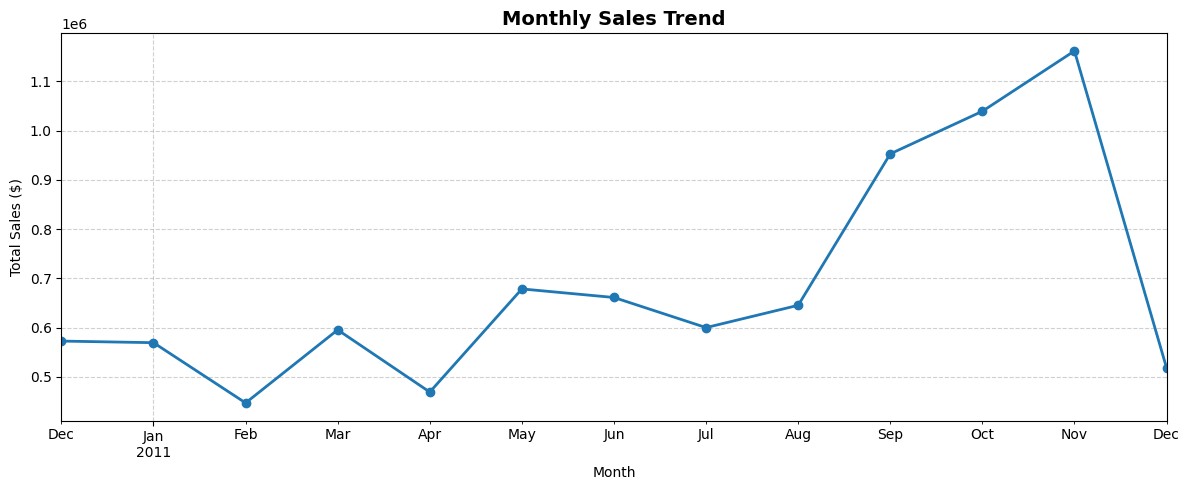

=== TOP 10 BEST-SELLING PRODUCTS BY REVENUE ===
PAPER CRAFT , LITTLE BIRDIE              $168,469.60
REGENCY CAKESTAND 3 TIER                 $142,592.95
WHITE HANGING HEART T-LIGHT HOLDER       $100,448.15
JUMBO BAG RED RETROSPOT                  $85,220.78
MEDIUM CERAMIC TOP STORAGE JAR           $81,416.73
POSTAGE                                  $77,821.96
PARTY BUNTING                            $68,844.33
ASSORTED COLOUR BIRD ORNAMENT            $56,580.34
Manual                                   $53,779.93
RABBIT NIGHT LIGHT                       $51,346.20


In [4]:
import matplotlib.pyplot as plt

# Monthly Sales Trend
df_clean['YearMonth'] = df_clean['InvoiceDate'].dt.to_period('M')
monthly_sales = df_clean.groupby('YearMonth')['TotalSales'].sum()

plt.figure(figsize=(12, 5))
monthly_sales.plot(kind='line', marker='o', color='#1f77b4', linewidth=2)
plt.title('Monthly Sales Trend', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Total Sales ($)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Top 10 Best-Selling Products
top_products = df_clean.groupby('Description')['TotalSales'].sum().sort_values(ascending=False).head(10)
print("=== TOP 10 BEST-SELLING PRODUCTS BY REVENUE ===")
for item, value in top_products.items():
    print(f"{item:<40} ${value:,.2f}")

In [6]:
import datetime as dt
import pandas as pd

# 1. Set snapshot date for Recency (1 day after the latest transaction)
snapshot_date = df_clean['InvoiceDate'].max() + dt.timedelta(days=1)

# 2. Group by Customer ID to calculate Recency, Frequency, Monetary values
rfm = df_clean.groupby('Customer ID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,  # Recency
    'Invoice': 'nunique',                                    # Frequency
    'TotalSales': 'sum'                                      # Monetary
}).reset_index()

rfm.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary']

# 3. Assign RFM Scores (1 to 4 scale)
rfm['R_Score'] = pd.qcut(rfm['Recency'], q=4, labels=[4, 3, 2, 1])
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=4, labels=[1, 2, 3, 4])
rfm['M_Score'] = pd.qcut(rfm['Monetary'], q=4, labels=[1, 2, 3, 4])

# 4. Calculate total RFM score
rfm['RFM_Score'] = rfm['R_Score'].astype(int) + rfm['F_Score'].astype(int) + rfm['M_Score'].astype(int)

# 5. Map into business customer segments
def segment_customer(row):
    if row['RFM_Score'] >= 10:
        return 'VIP / Champions'
    elif row['RFM_Score'] >= 8:
        return 'Loyal Customers'
    elif row['RFM_Score'] >= 6:
        return 'At-Risk / Need Attention'
    else:
        return 'Lost / Hibernating'

rfm['Segment'] = rfm.apply(segment_customer, axis=1)

print("=== RFM CUSTOMER SEGMENTS ===")
print(rfm['Segment'].value_counts())
rfm.head()

=== RFM CUSTOMER SEGMENTS ===
Segment
Lost / Hibernating          1291
VIP / Champions             1268
At-Risk / Need Attention     936
Loyal Customers              843
Name: count, dtype: int64


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346,326,1,77183.60,1,1,4,6,At-Risk / Need Attention
1,12347,2,7,4310.00,4,4,4,12,VIP / Champions
2,12348,75,4,1797.24,2,3,4,9,Loyal Customers
3,12349,19,1,1757.55,3,1,4,8,Loyal Customers
4,12350,310,1,334.40,1,1,2,4,Lost / Hibernating


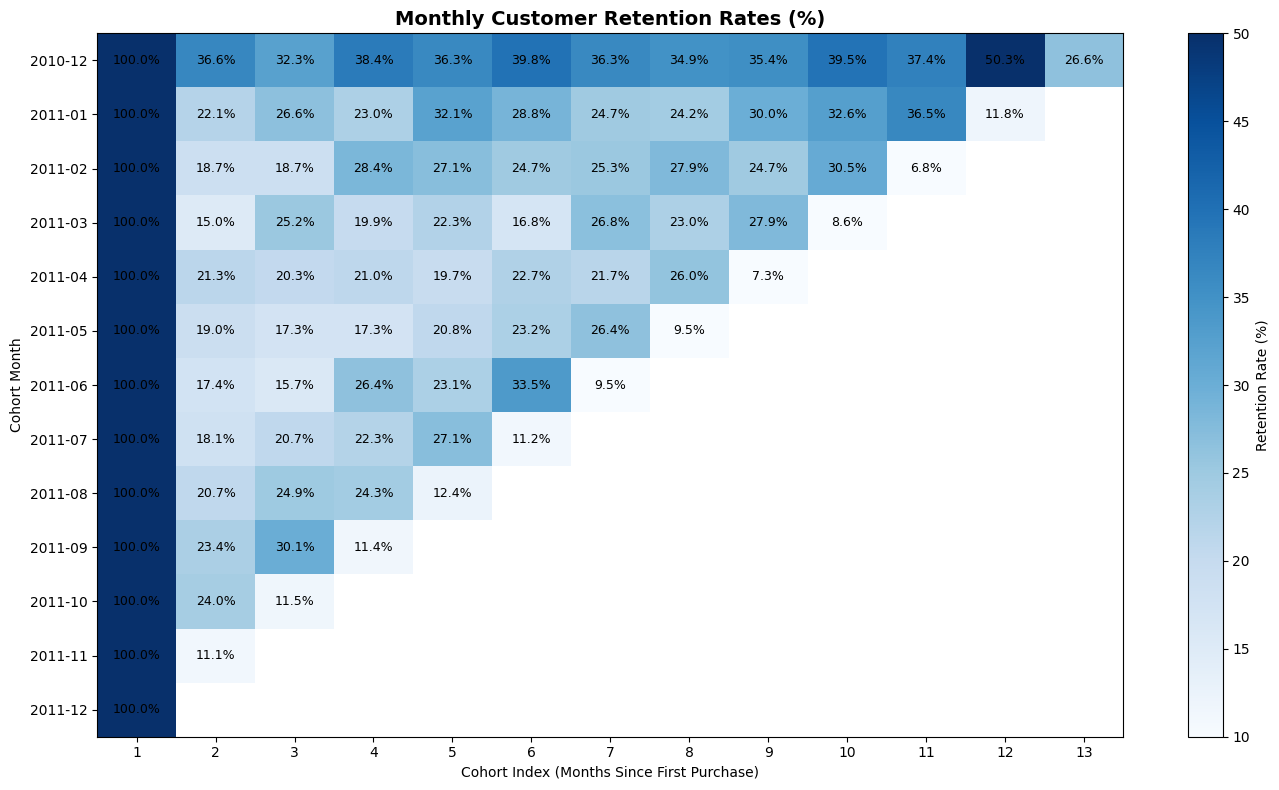

In [7]:
import matplotlib.pyplot as plt

# 1. Get Cohort Month (first purchase month)
df_clean['InvoiceMonth'] = df_clean['InvoiceDate'].dt.to_period('M')
df_clean['CohortMonth'] = df_clean.groupby('Customer ID')['InvoiceMonth'].transform('min')

# 2. Calculate Cohort Index (months elapsed)
def get_month_int(df, column):
    return df[column].dt.year * 12 + df[column].dt.month

invoice_year_month = get_month_int(df_clean, 'InvoiceMonth')
cohort_year_month = get_month_int(df_clean, 'CohortMonth')

df_clean['CohortIndex'] = invoice_year_month - cohort_year_month + 1

# 3. Build Retention Matrix
cohort_data = df_clean.groupby(['CohortMonth', 'CohortIndex'])['Customer ID'].nunique().reset_index()
cohort_counts = cohort_data.pivot(index='CohortMonth', columns='CohortIndex', values='Customer ID')

cohort_sizes = cohort_counts.iloc[:, 0]
retention = cohort_counts.divide(cohort_sizes, axis=0) * 100

# 4. Plot Heatmap using Matplotlib
plt.figure(figsize=(14, 8))
plt.imshow(retention, cmap='Blues', aspect='auto', vmin=10, vmax=50)

for i in range(retention.shape[0]):
    for j in range(retention.shape[1]):
        val = retention.iloc[i, j]
        if not pd.isna(val):
            plt.text(j, i, f'{val:.1f}%', ha='center', va='center', color='black', fontsize=9)

plt.title('Monthly Customer Retention Rates (%)', fontsize=14, fontweight='bold')
plt.xlabel('Cohort Index (Months Since First Purchase)')
plt.ylabel('Cohort Month')
plt.xticks(range(retention.shape[1]), retention.columns)
plt.yticks(range(retention.shape[0]), [str(x) for x in retention.index])
plt.colorbar(label='Retention Rate (%)')
plt.tight_layout()
plt.show()

In [8]:
# Save clean transactional dataset with Cohort attributes
df_clean.to_csv(r'C:\Users\punee\OneDrive\Desktop\Capstone\online_retail_cleaned.csv', index=False)

# Save customer-level RFM segment table
rfm.to_csv(r'C:\Users\punee\OneDrive\Desktop\Capstone\rfm_segments.csv', index=False)

print("CSVs exported successfully! Ready for Power BI / Tableau.")

CSVs exported successfully! Ready for Power BI / Tableau.
